In [ ]:
# un fichier JSON est simplement une façon de stocker des données structurées.

# etape 1 : La première étape sera de lire le fichier et le transformer en dataframe

import pandas as pd
import json
import matplotlib.pyplot as plt

   #info pour transformer un  json en dataframe pd 
def load_json(df):
    with open(df, "r", encoding="utf-8") as f:
        data = json.load(f)
        df = pd.json_normalize(data)
        print("Type des données :", type(data))
    return df

# etape 2 : Explorer les données
def print_all_info(df) : 
    print("===== DESCRIPTION =====")
    print(df.describe().to_string())

    print("===== SHAPE =====")
    print(df.shape)
    
    print("===== HEAD =====")
    print(df.head().to_string())

    print("===== COLONNES =====")
    print(list(df.columns))

    print("===== INFO =====")
    df.info()

# etape 3 : identifier les problèmes les valeurs manquantes
def missing_values(df):
    unkown_values = df.isna().sum()
    print("Nombre de valeurs manquantes :",unkown_values)

# etape 3 : identifier les problèmes les doublons
def drop_doublons(col,df):
    doublons = df[col].duplicated().sum()
    print(f"Nombre de doublons : {doublons}")
    if doublons >= 1:
       df = df.drop_duplicates(subset=[col])
    else:
        print("no doublons")

# etape 4 : valeurs abérrantes 
def outlayers(df):
    for col in df.select_dtypes(include=['float64', 'int64']).columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        print(f"Nombre de valeurs aberrantes dans la colonne {col} : {len(outliers)}")

#etape 4 : valeurs aberrantes et boxplot sur une colonne 
def outlayers_col(df,col):

    # Boxplot
    plt.figure(figsize=(8, 4))
    plt.boxplot(df[col].dropna())
    plt.title(f"Boxplot de {col}")
    plt.show()

    # Calcul IQR
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < borne_inf) |
        (df[col] > borne_sup)
    ]

    print(f"Nombre d'outliers : {len(outliers)}")
    print(outliers)

    return outliers
 




In [105]:
import requests
import pandas as pd
from io import BytesIO


class APIClient:
    """Client pour récupérer les données de Paris Open Data."""

    VELIB_URL = (
        "https://opendata.paris.fr/api/explore/v2.1/"
        "catalog/datasets/velib-disponibilite-en-temps-reel/"
        "exports/csv?use_labels=true"
    )
    METEO_URL = (
        "https://public-api.meteofrance.fr/public/DPObs/v2"
        "station/infrahoraire-6m?id_station=75&format=json"
    )

    def __init__(self, dataset, timeout: int = 30):
        self.timeout = timeout
        self.session = requests.Session()

        self.choose_dataset(dataset)

    def choose_dataset(self, dataset: str) -> None:
        """Choisit le dataset à récupérer."""
        if dataset == "velib":
            self.dataset_url = self.VELIB_URL
        elif dataset == "meteo":
            self.dataset_url = self.METEO_URL
        else:
            raise ValueError("Dataset inconnu. Choisissez 'velib' ou 'meteo'.")

    def get_dataset(self) -> pd.DataFrame:
        """Récupère le CSV et le convertit en DataFrame."""

        if self.dataset_url == self.VELIB_URL:
            response = self.session.get(
                self.dataset_url,
                timeout=self.timeout,
            )
        elif self.dataset_url == self.METEO_URL:
            response = self.session.get(
                self.dataset_url,
                timeout=self.timeout,
                apikey="YOUR_API_KEY"  # Remplacez par votre clé API
            )
        response.raise_for_status()

        # Le CSV de Velib est encodé en UTF-8, celui de la météo en ISO-8859-1
        if self.dataset_url == self.VELIB_URL:
            # Le CSV de la météo est encodé en ISO-8859-1
            return pd.read_csv(
                BytesIO(response.content),
                encoding="utf-8-sig",
                sep=None,
                engine="python",
            )
        elif self.dataset_url == self.METEO_URL:
            # Le retour de la météo est un JSON, on le convertit en DataFrame
            return pd.DataFrame(response.json())



    def close(self) -> None:
        self.session.close()

    def __enter__(self):
        return self

    def __exit__(self, exc_type, exc_value, traceback):
        self.close()

In [108]:
def main():
    with APIClient("velib") as client:
        # Récupération des données
        return client.get_dataset()

        # Étape suivante :
        # nettoyer et transformer les données reçues
        # velib_clean = ...
        # meteo_clean = ...


In [109]:
main()

,Identifiant station,Nom station,Station en fonctionnement,Capacité de la station,Nombre bornettes libres,Nombre total vélos disponibles,Vélos mécaniques disponibles,Vélos électriques disponibles,Borne de paiement disponible,Retour vélib possible,Actualisation de la donnée,Coordonnées géographiques,Nom communes équipées,Code INSEE communes équipées,station_opening_hours
0,32017,Basilique,OUI,22,14,8,3,5,OUI,OUI,2026-10-16T14:52:29+00:00,"48.93626891059109, 2.3588666820200914",Saint-Denis,93066,NaN
1,8026,Messine - Place Du Pérou,OUI,12,7,4,3,1,OUI,OUI,2026-10-16T14:53:16+00:00,"48.875448033960744, 2.315508019010038",Paris,75056,NaN
2,6003,Saint-Sulpice,OUI,21,12,7,4,3,OUI,OUI,2026-10-16T14:49:14+00:00,"48.85165383178419, 2.3308077827095985",Paris,75056,NaN
3,33006,André Karman - République,OUI,31,20,9,9,0,OUI,OUI,2026-10-16T14:51:39+00:00,"48.91039875761846, 2.3851355910301213",Aubervilliers,93001,NaN
4,30002,Jean Rostand - Paul Vaillant Couturier,OUI,40,9,29,8,21,OUI,OUI,2026-10-16T14:52:24+00:00,"48.908168131015, 2.4530601033354",Bobigny,93008,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1514,5202,Arbalète - Claude Bernard,OUI,34,24,10,6,4,OUI,OUI,2026-10-16T14:53:11+00:00,"48.840008992, 2.347522975107",Paris,75056,NaN
1515,4016,Lobau - Hôtel de Ville,OUI,60,18,40,40,0,OUI,OUI,2026-10-16T14:53:06+00:00,"48.8562118, 2.3532536",Paris,75056,NaN
1516,15056,Place Balard,OUI,22,14,15,13,2,OUI,OUI,2026-10-16T14:52:49+00:00,"48.836395736424, 2.2784192115068",Paris,75056,NaN
1517,12105,Bercy - Villot,OUI,33,1,35,23,12,OUI,OUI,2026-10-16T14:52:04+00:00,"48.841795009027, 2.3767850184816",Paris,75056,NaN


In [110]:
print_all_info(main())

===== DESCRIPTION =====
       Identifiant station  Capacité de la station  Nombre bornettes libres  Nombre total vélos disponibles  Vélos mécaniques disponibles  Vélos électriques disponibles  Code INSEE communes équipées  station_opening_hours
count          1519.000000             1519.000000              1519.000000                     1519.000000                   1519.000000                    1519.000000                   1519.000000                    0.0
mean          19267.863726               32.845951                20.490454                       11.337064                      7.260698                       4.076366                  81197.925609                    NaN
std           12465.274809               18.875606                19.030203                       11.900649                     10.268489                       4.685437                   8494.650318                    NaN
min            1001.000000                0.000000                 0.000000             

In [111]:
missing_values(main())

Nombre de valeurs manquantes : Identifiant station                  0
Nom station                          0
Station en fonctionnement            0
Capacité de la station               0
Nombre bornettes libres              0
Nombre total vélos disponibles       0
Vélos mécaniques disponibles         0
Vélos électriques disponibles        0
Borne de paiement disponible         0
Retour vélib possible                0
Actualisation de la donnée           0
Coordonnées géographiques            0
Nom communes équipées                0
Code INSEE communes équipées         0
station_opening_hours             1519
dtype: int64


In [112]:
drop_doublons("Nom station", main())

Nombre de doublons : 3


In [113]:
df_velib = main()
valeur_max = df_velib[df_velib.notnull()]['Nombre total vélos disponibles'].max()
print(valeur_max)


73


In [114]:
outlayers(df_velib)

Nombre de valeurs aberrantes dans la colonne Identifiant station : 166
Nombre de valeurs aberrantes dans la colonne Capacité de la station : 47
Nombre de valeurs aberrantes dans la colonne Nombre bornettes libres : 18
Nombre de valeurs aberrantes dans la colonne Nombre total vélos disponibles : 69
Nombre de valeurs aberrantes dans la colonne Vélos mécaniques disponibles : 90
Nombre de valeurs aberrantes dans la colonne Vélos électriques disponibles : 97
Nombre de valeurs aberrantes dans la colonne Code INSEE communes équipées : 0
Nombre de valeurs aberrantes dans la colonne station_opening_hours : 0


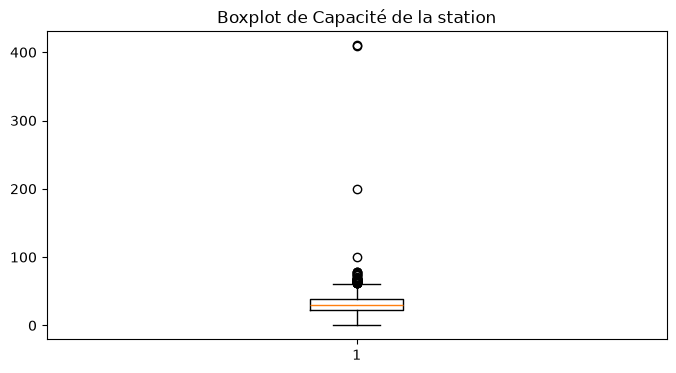

Nombre d'outliers : 47
      Identifiant station                                 Nom station  \
25                  13118                            Regnault - Patay   
56                  11023                       Saint-Maur - Roquette   
67                  15104           Hôpital Européen Georges Pompidou   
149                 11007                       Jean Macé - Faidherbe   
156                 16124        Route de Sèvres - Porte de Bagatelle   
165                  7009                         Assemblée Nationale   
197                 15038          Place Adolphe Cherioux - Vaugirard   
249                 15003               Gare Montparnasse - Vaugirard   
260                 15059                          Parc André Citroën   
301                 12507               Hippodrome de Paris Vincennes   
331                 32021      Place du Front Populaire - George Sand   
409                 21306                             Place Lafayette   
461                 15008   

,Identifiant station,Nom station,Station en fonctionnement,Capacité de la station,Nombre bornettes libres,Nombre total vélos disponibles,Vélos mécaniques disponibles,Vélos électriques disponibles,Borne de paiement disponible,Retour vélib possible,Actualisation de la donnée,Coordonnées géographiques,Nom communes équipées,Code INSEE communes équipées
25,13118,Regnault - Patay,OUI,63,4,58,54,4,OUI,OUI,2026-10-16T14:52:21+00:00,"48.82435782216384, 2.377065159380436",Paris,75056
56,11023,Saint-Maur - Roquette,OUI,65,49,14,14,0,OUI,OUI,2026-10-16T14:52:31+00:00,"48.858688774063, 2.3835539945715",Paris,75056
67,15104,Hôpital Européen Georges Pompidou,OUI,78,8,69,63,6,OUI,OUI,2026-10-16T14:53:02+00:00,"48.837695319163, 2.2753742337227",Paris,75056
149,11007,Jean Macé - Faidherbe,OUI,78,5,73,70,3,OUI,OUI,2026-10-16T14:53:15+00:00,"48.85337548426, 2.3828620836139",Paris,75056
156,16124,Route de Sèvres - Porte de Bagatelle,OUI,66,2,61,60,1,OUI,OUI,2026-10-16T14:52:57+00:00,"48.87525984132485, 2.249415814876557",Paris,75056
165,7009,Assemblée Nationale,OUI,76,59,16,11,5,OUI,OUI,2026-10-16T14:49:40+00:00,"48.861411014652, 2.3201214185208",Paris,75056
197,15038,Place Adolphe Cherioux - Vaugirard,OUI,63,52,10,3,7,OUI,OUI,2026-10-16T14:51:59+00:00,"48.83959442800459, 2.3010657727718353",Paris,75056
249,15003,Gare Montparnasse - Vaugirard,OUI,66,2,64,3,61,OUI,OUI,2026-10-16T14:52:27+00:00,"48.8418071798797, 2.31951002690117",Paris,75056
260,15059,Parc André Citroën,OUI,65,19,43,40,3,OUI,OUI,2026-10-16T14:53:16+00:00,"48.840639944297, 2.2780618071556",Paris,75056
301,12507,Hippodrome de Paris Vincennes,OUI,100,97,3,2,1,NON,NON,2025-11-13T16:03:03+00:00,"48.820484866661, 2.4502807724015",Paris,75056


In [120]:
outlayers_col(df_velib, 'Capacité de la station')

In [115]:
df_velib = df_velib.drop(columns=['station_opening_hours'])


In [116]:
df_velib

,Identifiant station,Nom station,Station en fonctionnement,Capacité de la station,Nombre bornettes libres,Nombre total vélos disponibles,Vélos mécaniques disponibles,Vélos électriques disponibles,Borne de paiement disponible,Retour vélib possible,Actualisation de la donnée,Coordonnées géographiques,Nom communes équipées,Code INSEE communes équipées
0,32017,Basilique,OUI,22,14,8,3,5,OUI,OUI,2026-10-16T14:52:29+00:00,"48.93626891059109, 2.3588666820200914",Saint-Denis,93066
1,8026,Messine - Place Du Pérou,OUI,12,7,4,3,1,OUI,OUI,2026-10-16T14:53:16+00:00,"48.875448033960744, 2.315508019010038",Paris,75056
2,6003,Saint-Sulpice,OUI,21,12,7,4,3,OUI,OUI,2026-10-16T14:49:14+00:00,"48.85165383178419, 2.3308077827095985",Paris,75056
3,33006,André Karman - République,OUI,31,20,9,9,0,OUI,OUI,2026-10-16T14:51:39+00:00,"48.91039875761846, 2.3851355910301213",Aubervilliers,93001
4,30002,Jean Rostand - Paul Vaillant Couturier,OUI,40,9,29,8,21,OUI,OUI,2026-10-16T14:52:24+00:00,"48.908168131015, 2.4530601033354",Bobigny,93008
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1514,5202,Arbalète - Claude Bernard,OUI,34,24,10,6,4,OUI,OUI,2026-10-16T14:53:11+00:00,"48.840008992, 2.347522975107",Paris,75056
1515,4016,Lobau - Hôtel de Ville,OUI,60,18,40,40,0,OUI,OUI,2026-10-16T14:53:06+00:00,"48.8562118, 2.3532536",Paris,75056
1516,15056,Place Balard,OUI,22,14,15,13,2,OUI,OUI,2026-10-16T14:52:49+00:00,"48.836395736424, 2.2784192115068",Paris,75056
1517,12105,Bercy - Villot,OUI,33,1,35,23,12,OUI,OUI,2026-10-16T14:52:04+00:00,"48.841795009027, 2.3767850184816",Paris,75056


In [ ]:
# je veux supprimer les lignes où Capacité de la station = 410 / 409 / 200 


In [ ]:
df_velib['Pourcent availability'] = df_velib['Nombre total vélos disponibles']/df_velib['Capacité de la station']*100
df_velib